# v34 — per-seed 候補(tw/self/nbr × pf_1/2/3 × 32seed)+クロスソース採点
v33 の結論=「枠組みは機能する(ext_vote AUC0.82, 学習ゲート6.749<hedge6.796)が、**候補不足**
(モードoracle6.240=自由シフト上限4.449の26%)」。v34 はそのボトルネックに投資する:

- **A: 候補の拡充** — smooth PF の **per-seed 32本 × 2系統(smooth平滑/forward生) × 3ソース(tw/self/nbr)
  × 3param(pf_1/2/3) = 576本**(`v34/dump_seeds_v34.py` の出力)を候補プールに追加(+v33 の平均参照9本)。
  seed重み ww(尤度温度付き)と、どのpf/ソース/系統から来たかのメタデータも特徴に使う。
- **B: クロスソース採点** — 各候補モードの軌跡を **tw/self/nbr grid で採点**し、
  「blendより外部証拠に合うか」のマージンを特徴に(ext_vote の連続値・軌跡版)。

ゲート: ①モードoracle の回収率 26%→? ②新特徴(seed事後質量/クロス採点)のAUC ③学習ゲートOOFが
**v33 の 6.7492** を下回るか(勝てば submit のhedge置換候補が更新)。


In [1]:
# ===== ロード: blend OOF + 平均参照9本(v33同一) + per-seed dump =====
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
warnings.filterwarnings("ignore")
matplotlib.rcParams["font.family"] = "Meiryo"; matplotlib.rcParams["axes.unicode_minus"] = False

PROJECT = Path(r"C:\Users\kosaka256\Documents\rogii_claude")
V28_ART = PROJECT / "v28" / "artifacts_v28"
V29_ART = PROJECT / "v29" / "artifacts_v29"
V29B    = PROJECT / "v29" / "artifacts_v29b"
V32_ART = PROJECT / "v32" / "artifacts_v32"
V34_ART = PROJECT / "v34" / "artifacts_v34"
ART = V34_ART; ART.mkdir(parents=True, exist_ok=True)

REF_COLS = [("tw", 1, "pf_ancc_1"), ("tw", 2, "pf_ancc_2"), ("tw", 3, "pf_ancc_3"),
            ("self", 1, "pf_self_1"), ("self", 2, "pf_self_2"), ("self", 3, "pf_self_3"),
            ("nbr", 1, "pf_nbr_1"), ("nbr", 2, "pf_nbr_2"), ("nbr", 3, "pf_nbr_3")]
cols = (["well", "target", "last_known_tvt", "md_since", "pf_ancc",
         "pf_nbr_has", "pf_nbr_nrefs", "pf_nbr_nndist"] + [c for _, _, c in REF_COLS])
tbl = pq.read_table(V28_ART / "data" / "train.parquet", columns=cols)
col = {c: tbl.column(c).to_numpy(zero_copy_only=False) for c in cols if c != "well"}
g = tbl.column("well").to_pandas().to_numpy()
y   = col["target"].astype(np.float64)
lk  = col["last_known_tvt"].astype(np.float64)
mds = col["md_since"].astype(np.float64)
pfa = col["pf_ancc"].astype(np.float64)
tvt_true = lk + y

gbm = np.load(V29_ART / "gbm_oof.npy")
nnz = np.load(V29B / "nn_oof_combo.npz")
nn_ens = np.mean([nnz[k] for k in nnz.files], axis=0)
w_nn = float(json.loads((V29B / "results.json").read_text())["combo"]["blend_w"])
pp = json.loads((V28_ART / "pp_params.json").read_text())
def apply_pp(res):
    dd = res * (1 - pp["w_pf"]) + (pfa - lk) * pp["w_pf"]
    return lk + dd * (1.0 - np.exp(-np.maximum(mds, 0.0) / float(pp["tau"]))) * pp.get("alpha", 1.0)
blend  = apply_pp((1 - w_nn) * gbm + w_nn * nn_ens)
pred_g = apply_pp(gbm); pred_n = apply_pp(nn_ens)

wid = pd.unique(g)
rows_of = {w: np.where(g == w)[0] for w in wid}
def rmse(e):
    e = e[np.isfinite(e)]
    return float(np.sqrt(np.mean(e ** 2))) if e.size else np.nan
e0 = blend - tvt_true
base_overall = rmse(e0)
per_base = {w: rmse(e0[rows_of[w]]) for w in wid}
HARD = set(pd.read_csv(V32_ART / "hardcore_diag.csv", index_col=0).query(
    "rmse_prior >= 10 and abs(bias) > 8").index) & set(wid)
WNBR = {w: bool(np.nanmean(col["pf_nbr_has"][rows_of[w]]) > 0.5) for w in wid}

# 平均参照9本のオフセット(v33同一)
OBS = {}
for w in wid:
    r = rows_of[w]
    refs = {}
    for src, pset, c in REF_COLS:
        if src == "nbr" and not WNBR[w]:
            continue
        v = col[c][r].astype(np.float64) - blend[r]
        if np.isfinite(v).sum() < max(10, 0.3 * len(r)):
            continue
        refs[(src, pset)] = float(np.nanmedian(v))
    OBS[w] = refs

DUMPS = {k: np.load(V34_ART / f"seed_dump_pf{k}.npz") for k in (1, 2, 3)}
KEYS = {k: set(DUMPS[k].files) for k in (1, 2, 3)}
n_seed_wells = sum(1 for w in wid if f"{w}|ps_tw" in KEYS[1])
print(f"blend OOF overall = {base_overall:.4f} | wells {len(wid)} | 硬い核 {len(HARD)} | seed dumpあり {n_seed_wells}井戸")


blend OOF overall = 6.8711 | wells 773 | 硬い核 27 | seed dumpあり 773井戸


seed候補/井戸: median=576 max=576(期待値: nbrあり576 / なし384。大きく下回る井戸はNaN落ち)
  期待値どおりの井戸: 773/773
base 6.8711 / 自由シフト上限 4.4494
モードoracle: 平均9本のみ 6.2579(回収25%, v33≈6.2403/26%)
              per-seedのみ 6.1003(回収32%)
              ★併合       6.1180(回収31%)
seed候補による新規カバー(参照9本では stay だった井戸で非ゼロ選択): 7井戸
非ゼロ選択 35井戸(硬い核 8/27)


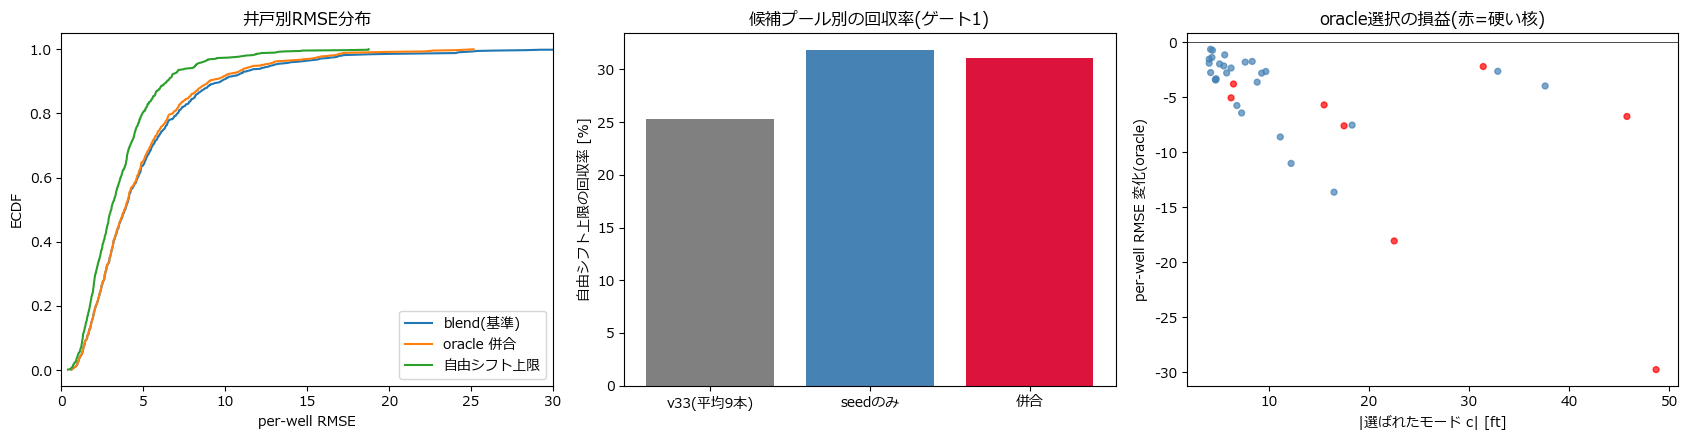

In [2]:
# ===== ゲート1: 候補プール(平均9本 vs per-seed 288本 vs 併合)でモードoracle比較 =====
GAP_LINK = 8.0; MODE_MIN, MODE_MAX = 4.0, 60.0   # v33と同一(比較可能性のため)
SRCS = ("tw", "self", "nbr")
FLTS = (("sm", "ps"), ("fw", "pfw"))   # sm=固定ラグ平滑 / fw=forward(平滑なし)

ITEMS = {}   # w -> list(dict(kind,src,pset,flt,d,wt[,sid]))
for w in wid:
    r = rows_of[w]; it = []
    for (src, pset), d in OBS[w].items():
        it.append(dict(kind="ref", src=src, pset=pset, flt="", d=d, wt=1.0))
    for k in (1, 2, 3):
        z = DUMPS[k]
        for src in SRCS:
            if src == "nbr" and not WNBR[w]:
                continue        # nbr無し井戸のnbrパスは tw フォールバック実行なので除外
            for flt, pref in FLTS:
                key = f"{w}|{pref}_{src}"
                if key not in KEYS[k]:
                    continue
                ps = z[key]; ww_ = z[f"{w}|ww_{src}"]
                T = min(ps.shape[1], len(r))
                dmed = np.nanmedian(ps[:, :T].astype(np.float64) - blend[r[:T]][None, :], axis=1)
                for s in range(ps.shape[0]):
                    if np.isfinite(dmed[s]):
                        it.append(dict(kind="seed", src=src, pset=k, flt=flt,
                                       d=float(dmed[s]), wt=float(ww_[s]), sid=s))
    ITEMS[w] = it

# サニティチェック: seed候補が32本×run数だけ漏れなく入っているか
n_seed_items = np.array([sum(1 for x in ITEMS[w] if x["kind"] == "seed") for w in wid])
exp_nbr, exp_no = 32 * 3 * 2 * 3, 32 * 2 * 2 * 3   # nbrあり=576 / なし=384(NaN落ち分だけ減る)
print(f"seed候補/井戸: median={np.median(n_seed_items):.0f} max={n_seed_items.max()}"
      f"(期待値: nbrあり{exp_nbr} / なし{exp_no}。大きく下回る井戸はNaN落ち)")
print(f"  期待値どおりの井戸: {int(np.sum((n_seed_items == exp_nbr) | (n_seed_items == exp_no)))}/{len(wid)}")

def cluster_items(items):
    its = sorted(items, key=lambda x: x["d"])
    if not its:
        return []
    groups, cur = [], [its[0]]
    for x in its[1:]:
        if x["d"] - cur[-1]["d"] > GAP_LINK:
            groups.append(cur); cur = [x]
        else:
            cur.append(x)
    groups.append(cur)
    out = []
    for m in groups:
        ds = np.array([x["d"] for x in m]); wts = np.array([x["wt"] for x in m])
        o = np.argsort(ds); cw = np.cumsum(wts[o])
        c = float(ds[o][min(np.searchsorted(cw, cw[-1] / 2), len(ds) - 1)])   # 重み付き中央値
        out.append(dict(c=c, members=m, spread=float(np.std(ds)) if len(ds) > 1 else 0.0))
    return out

def oracle(sel):
    e = e0.copy(); picks, per = {}, {}
    for w in wid:
        modes = cluster_items([x for x in ITEMS[w] if sel(x)])
        cands = [0.0] + [m["c"] for m in modes if MODE_MIN <= abs(m["c"]) <= MODE_MAX]
        r = rows_of[w]; ew = e0[r]
        sc = [rmse(ew + c) for c in cands]
        j = int(np.argmin(sc)); picks[w] = cands[j]; per[w] = sc[j]; e[r] = ew + cands[j]
    return rmse(e), picks, per

or_ref, pick_ref, _ = oracle(lambda x: x["kind"] == "ref")
or_seed, _, _ = oracle(lambda x: x["kind"] == "seed")
or_all, pick, per_or = oracle(lambda x: True)
per_fs = {}; e_fs = e0.copy()
for w in wid:
    r = rows_of[w]; mu = np.nanmean(e0[r]); per_fs[w] = rmse(e0[r] - mu); e_fs[r] = e0[r] - mu
fs_overall = rmse(e_fs)
rec = lambda v: 100 * (base_overall - v) / max(base_overall - fs_overall, 1e-9)
print(f"base {base_overall:.4f} / 自由シフト上限 {fs_overall:.4f}")
print(f"モードoracle: 平均9本のみ {or_ref:.4f}(回収{rec(or_ref):.0f}%, v33≈6.2403/26%)")
print(f"              per-seedのみ {or_seed:.4f}(回収{rec(or_seed):.0f}%)")
print(f"              ★併合       {or_all:.4f}(回収{rec(or_all):.0f}%)")
new_cov = [w for w in wid if pick[w] != 0.0 and pick_ref[w] == 0.0]
print(f"seed候補による新規カバー(参照9本では stay だった井戸で非ゼロ選択): {len(new_cov)}井戸")
print(f"非ゼロ選択 {sum(1 for w in wid if pick[w] != 0.0)}井戸(硬い核 {sum(1 for w in HARD if pick[w] != 0.0)}/{len(HARD)})")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for lab, pw in [("blend(基準)", per_base), ("oracle 併合", per_or), ("自由シフト上限", per_fs)]:
    v = np.sort([pw[w] for w in wid]); ax[0].plot(v, np.arange(1, len(v) + 1) / len(v), label=lab)
ax[0].set_xlim(0, 30); ax[0].set_xlabel("per-well RMSE"); ax[0].set_ylabel("ECDF"); ax[0].legend()
ax[0].set_title("井戸別RMSE分布")
ax[1].bar(["v33(平均9本)", "seedのみ", "併合"], [rec(or_ref), rec(or_seed), rec(or_all)],
          color=["gray", "steelblue", "crimson"])
ax[1].set_ylabel("自由シフト上限の回収率 [%]"); ax[1].set_title("候補プール別の回収率(ゲート1)")
nz = [w for w in wid if pick[w] != 0.0]
ax[2].scatter([abs(pick[w]) for w in nz], [per_or[w] - per_base[w] for w in nz],
              c=["red" if w in HARD else "steelblue" for w in nz], s=18, alpha=0.7)
ax[2].axhline(0, c="k", lw=0.5); ax[2].set_xlabel("|選ばれたモード c| [ft]")
ax[2].set_ylabel("per-well RMSE 変化(oracle)"); ax[2].set_title("oracle選択の損益(赤=硬い核)")
plt.tight_layout(); plt.show()


In [3]:
# ===== B: クロスソース採点 — モード軌跡(メンバーseedのww加重平均)を tw/self/nbr grid で採点 =====
def score_traj(traj, gg, gmin, gst, gs, gr):
    G = len(gg)
    ii = np.clip((np.asarray(traj, float) - gmin) / gst, 0.0, G - 1.000001)
    i0 = np.floor(ii).astype(int); t = ii - i0
    eg = gg[i0] * (1 - t) + gg[np.minimum(i0 + 1, G - 1)] * t
    m = np.isfinite(gr) & np.isfinite(eg)
    if m.sum() < 10:
        return np.nan
    d = (gr[m] - eg[m]) / gs
    return float(np.mean(np.exp(-0.5 * d * d)))

MODES = {w: [m for m in cluster_items(ITEMS[w]) if MODE_MIN <= abs(m["c"]) <= MODE_MAX] for w in wid}
PHYS_KEYS = ("rough_ratio", "dip_dev", "dip_absmax", "geo_jump", "smfw_gap", "edge_frac", "tail_dev", "ll_margin")
XM = {}    # (w, mode_idx) -> dict(xm_tw, xm_self, xm_nbr)
PHYS = {}  # (w, mode_idx) -> 物理/荒れ具合特徴
for w in wid:
    if not MODES[w]:
        continue
    r = rows_of[w]
    for mi, m in enumerate(MODES[w]):
        acc = {"tw": [], "self": [], "nbr": []}
        ph = {kk: [] for kk in PHYS_KEYS}
        for k in (1, 2, 3):
            dpz = DUMPS[k]
            if f"{w}|meta" not in KEYS[k]:
                continue
            gmin, gst, gs = dpz[f"{w}|meta"]; gr = dpz[f"{w}|gr"].astype(np.float64)
            md_ = dpz[f"{w}|md"].astype(np.float64); zz = dpz[f"{w}|z"].astype(np.float64)
            ir = float(dpz[f"{w}|ir"])
            T = min(len(r), len(gr), len(md_))
            trajs, wts, smfw, llm = [], [], [], []
            for src in SRCS:
                # 尤度マージン(このモードを支持するseedは他seedよりGR適合が良いか。対照群寄り)
                sids_src = {x["sid"] for x in m["members"]
                            if x["kind"] == "seed" and x["pset"] == k and x["src"] == src}
                if sids_src and f"{w}|ll_{src}" in KEYS[k]:
                    ll_ = dpz[f"{w}|ll_{src}"]; fin = np.isfinite(ll_)
                    if fin.sum() > 1 and np.nanstd(ll_[fin]) > 1e-9:
                        llm.append(float((np.nanmean(ll_[list(sids_src)]) - np.nanmean(ll_[fin]))
                                         / (np.nanstd(ll_[fin]) + 1e-9)))
                for flt, pref in FLTS:
                    key = f"{w}|{pref}_{src}"
                    if key not in KEYS[k]:
                        continue
                    sids = [x["sid"] for x in m["members"]
                            if x["kind"] == "seed" and x["pset"] == k and x["src"] == src and x["flt"] == flt]
                    if not sids:
                        continue
                    ps = dpz[key]; ww_ = dpz[f"{w}|ww_{src}"]
                    trajs.append(ps[sids, :T].astype(np.float64)); wts.append(np.asarray(ww_[sids], float))
                    other = f"{w}|{'pfw' if pref == 'ps' else 'ps'}_{src}"
                    if other in KEYS[k]:   # smooth↔forward 乖離(平滑がどれだけ直したか)
                        po = dpz[other]
                        smfw.append(float(np.nanmean(np.abs(
                            ps[sids, :T].astype(np.float64) - po[sids, :T].astype(np.float64)))))
            has_seed = bool(trajs)
            if has_seed:
                Tm = min(t_.shape[1] for t_ in trajs)
                allt = np.concatenate([t_[:, :Tm] for t_ in trajs], 0)
                allw = np.concatenate(wts)
                allw = allw / allw.sum() if allw.sum() > 1e-12 else np.full(len(allw), 1.0 / len(allw))
                traj = (allw[:, None] * allt).sum(0); Tk = Tm
            else:
                traj = blend[r[:T]] + m["c"]; Tk = T
            btraj = blend[r[:Tk]]
            # --- 物理/荒れ具合(seedメンバーがある時だけ=blend+cの縮退値でAUCを汚さない)---
            if has_seed and Tk >= 5:
                mdk = md_[:Tk]; zk = zz[:Tk]
                dmd = np.maximum(np.diff(mdk), 1.0)
                gt = np.diff(traj + zk) / dmd                       # geo_z 傾き(=実効dip)
                ph["dip_dev"].append(abs(float(np.nanmedian(gt)) - ir))
                ph["dip_absmax"].append(float(np.nanpercentile(np.abs(gt), 95)))
                ph["geo_jump"].append(float(np.nanmax(np.abs(np.diff(traj + zk)))))
                r2 = np.abs(np.diff(traj, 2)); b2 = np.abs(np.diff(btraj, 2))
                ph["rough_ratio"].append(float((np.nanmean(r2) + 1e-6) / (np.nanmean(b2) + 1e-6)))
                gmax = gmin + (len(dpz[f"{w}|gg_tw"]) - 1) * gst    # typewellレンジ端への張り付き
                ph["edge_frac"].append(float(np.mean((traj < gmin + 5.0) | (traj > gmax - 5.0))))
                th = Tk // 2                                        # 後半だけのオフセット整合
                ph["tail_dev"].append(abs(float(np.nanmedian((traj - btraj)[th:])) - m["c"]))
            if smfw:
                ph["smfw_gap"].append(float(np.mean(smfw)))
            if llm:
                ph["ll_margin"].append(float(np.mean(llm)))
            # --- クロスソース採点 ---
            for nmk, gk in [("tw", "gg_tw"), ("self", "gg_self"), ("nbr", "gg_nbr")]:
                key = f"{w}|{gk}"
                if key not in KEYS[k]:
                    continue
                gg = dpz[key].astype(np.float64)
                sm = score_traj(traj[:Tk], gg, gmin, gst, gs, gr[:Tk])
                sb = score_traj(btraj, gg, gmin, gst, gs, gr[:Tk])
                if np.isfinite(sm) and np.isfinite(sb):
                    acc[nmk].append(sm - sb)
        XM[(w, mi)] = {f"xm_{kk}": (float(np.mean(v)) if v else np.nan) for kk, v in acc.items()}
        PHYS[(w, mi)] = {kk: (float(np.mean(v)) if v else np.nan) for kk, v in ph.items()}
print(f"採点済みモード {len(XM)}(nbr gridあり率 {np.mean([np.isfinite(x['xm_nbr']) for x in XM.values()]):.0%})")


採点済みモード 456(nbr gridあり率 77%)


候補モード 456行 / 分裂井戸 334 / 正解モード 35(v33: 230行/163井戸/50)
fw_seed_mass    0.939
sm_seed_mass    0.939
ext_seed_mass   0.926
seed_frac       0.918
stay_share      0.896
n_pset_seed     0.887
tw_seed_mass    0.874
ext_vote        0.873
has_self        0.870
n_pset_ref      0.870
vote            0.870
n_src           0.865
geo_jump        0.860
has_tw          0.854
spread          0.844
c_abs           0.838
rough_ratio     0.813
n_src_seed      0.811
ll_margin       0.801
xm_tw           0.788
dip_absmax      0.780
xm_self         0.771
xm_nbr          0.770
has_nbr         0.707
nrefs           0.669
nndist          0.635
smfw_gap        0.634
dip_dev         0.628
d_gnn           0.614
tail_dev        0.550
md_len          0.539
n_rows          0.539
n_flt           0.526
has_opp         0.517
gnn_align       0.517
edge_frac       0.506
md_step         0.500


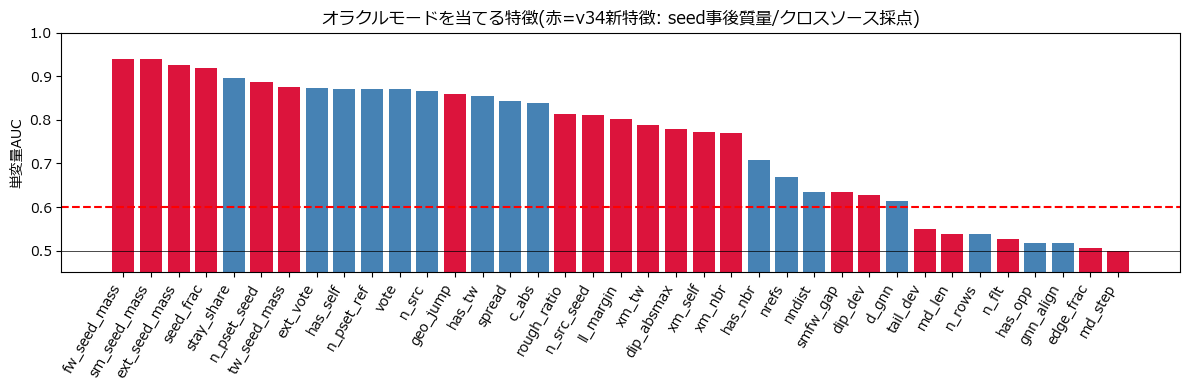

In [4]:
# ===== ゲート2: 特徴テーブル + 単変量AUC =====
from sklearn.metrics import roc_auc_score

wellstat = {}
for w in wid:
    r = rows_of[w]
    md_len = float(np.nanmax(mds[r])) if np.isfinite(mds[r]).any() else np.nan   # 評価ゾーンMD長
    wellstat[w] = dict(
        nrefs=float(np.nanmedian(col["pf_nbr_nrefs"][r])),
        nndist=float(np.nanmedian(col["pf_nbr_nndist"][r])),
        d_gnn=float(np.nanmedian(pred_n[r] - pred_g[r])),
        n_rows=float(len(r)), md_len=md_len,
        md_step=md_len / max(len(r), 1) if np.isfinite(md_len) else np.nan)

rows = []
for w in wid:
    if not MODES[w]:
        continue
    items = ITEMS[w]
    nref = max(sum(1 for x in items if x["kind"] == "ref"), 1)
    n_ext = sum(1 for x in items if x["kind"] == "ref" and x["src"] in ("self", "nbr"))
    tot_wt = sum(x["wt"] for x in items)
    stay_wt = sum(x["wt"] for m in cluster_items(items) if abs(m["c"]) < MODE_MIN for x in m["members"])
    flts = [f for f, _ in FLTS]
    runs_tw = [("tw", k, f) for k in (1, 2, 3) for f in flts]
    runs_ext = ([("self", k, f) for k in (1, 2, 3) for f in flts]
                + ([("nbr", k, f) for k in (1, 2, 3) for f in flts] if WNBR[w] else []))
    for mi, m in enumerate(MODES[w]):
        refs = [x for x in m["members"] if x["kind"] == "ref"]
        seeds = [x for x in m["members"] if x["kind"] == "seed"]
        srcs_ref = {x["src"] for x in refs}
        mass = {}   # (src,k,flt) -> このモード上のseed事後質量
        for x in seeds:
            kk = (x["src"], x["pset"], x["flt"])
            mass[kk] = mass.get(kk, 0.0) + x["wt"]
        ws_ = wellstat[w]; xm = XM.get((w, mi), {})
        rows.append(dict(
            well=w, c=m["c"], gain=per_base[w] - rmse(e0[rows_of[w]] + m["c"]),
            y=int(pick[w] != 0.0 and abs(pick[w] - m["c"]) < 1e-9),
            vote=len(refs) / nref,
            ext_vote=(sum(1 for x in refs if x["src"] in ("self", "nbr")) / n_ext) if n_ext else 0.0,
            stay_share=stay_wt / max(tot_wt, 1e-9),
            n_src=len(srcs_ref), has_nbr=int("nbr" in srcs_ref), has_self=int("self" in srcs_ref),
            has_tw=int("tw" in srcs_ref), n_pset_ref=len({x["pset"] for x in refs}),
            tw_seed_mass=float(np.mean([mass.get(rn, 0.0) for rn in runs_tw])),
            ext_seed_mass=float(np.mean([mass.get(rn, 0.0) for rn in runs_ext])) if runs_ext else 0.0,
            sm_seed_mass=float(np.mean([v for kk_, v in mass.items() if kk_[2] == "sm"])) if any(
                kk_[2] == "sm" for kk_ in mass) else 0.0,
            fw_seed_mass=float(np.mean([v for kk_, v in mass.items() if kk_[2] == "fw"])) if any(
                kk_[2] == "fw" for kk_ in mass) else 0.0,
            seed_frac=len(seeds) / max(sum(1 for x in items if x["kind"] == "seed"), 1),
            n_src_seed=len({x["src"] for x in seeds}), n_pset_seed=len({x["pset"] for x in seeds}),
            n_flt=len({x["flt"] for x in seeds}),
            c_abs=abs(m["c"]), spread=m["spread"],
            has_opp=int(any(np.sign(x["c"]) != np.sign(m["c"]) for x in MODES[w] if x is not m)),
            gnn_align=float(np.sign(m["c"]) * ws_["d_gnn"]),
            xm_tw=xm.get("xm_tw", np.nan), xm_self=xm.get("xm_self", np.nan), xm_nbr=xm.get("xm_nbr", np.nan),
            **PHYS.get((w, mi), {}), **ws_))
TBL = pd.DataFrame(rows)
print(f"候補モード {len(TBL)}行 / 分裂井戸 {TBL['well'].nunique()} / 正解モード {int(TBL['y'].sum())}(v33: 230行/163井戸/50)")

FEATS = ["vote", "ext_vote", "stay_share", "n_src", "has_nbr", "has_self", "has_tw", "n_pset_ref",
         "tw_seed_mass", "ext_seed_mass", "sm_seed_mass", "fw_seed_mass",
         "seed_frac", "n_src_seed", "n_pset_seed", "n_flt",
         "c_abs", "spread", "has_opp", "gnn_align",
         "xm_self", "xm_nbr", "xm_tw",
         "rough_ratio", "dip_dev", "dip_absmax", "geo_jump", "smfw_gap", "edge_frac", "tail_dev", "ll_margin",
         "nrefs", "nndist", "n_rows", "md_len", "md_step", "d_gnn"]
aucs = {}
for f in FEATS:
    v = TBL[f].to_numpy(dtype=float); m_ = np.isfinite(v)
    if m_.sum() < 30 or TBL["y"][m_].nunique() < 2:
        continue
    a = roc_auc_score(TBL["y"][m_], v[m_]); aucs[f] = max(a, 1 - a)
A = pd.Series(aucs).sort_values(ascending=False)
print(A.to_string(float_format="%.3f"))
fig, ax = plt.subplots(figsize=(12, 4))
newf = {"tw_seed_mass", "ext_seed_mass", "sm_seed_mass", "fw_seed_mass", "seed_frac",
        "n_src_seed", "n_pset_seed", "n_flt", "xm_self", "xm_nbr", "xm_tw",
        "rough_ratio", "dip_dev", "dip_absmax", "geo_jump", "smfw_gap", "edge_frac",
        "tail_dev", "ll_margin", "md_len", "md_step"}
ax.bar(A.index, A.values, color=["crimson" if f in newf else "steelblue" for f in A.index])
ax.axhline(0.6, c="r", ls="--"); ax.axhline(0.5, c="k", lw=0.5)
ax.set_ylabel("単変量AUC"); ax.set_ylim(0.45, 1.0)
ax.set_title("オラクルモードを当てる特徴(赤=v34新特徴: seed事後質量/クロスソース採点)")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()


OOF AUC: LGBM 0.907 / Logistic 0.924(v33: 0.768/0.801)
基準: blend 6.8711 / vote-hedge 6.7960 / ★v33学習ゲート 6.7492 / oracle併合 6.1180
                  rule  overall
       p_log post λ1.0 6.528834
       p_log post λ0.8 6.554378
       p_lgb soft λ1.0 6.583148
       p_lgb soft λ0.8 6.597412
       p_log post λ0.6 6.601942
       p_log soft λ1.0 6.604018
p_log hard λ0.4 p>=0.4 6.607531
       p_log soft λ0.8 6.612322
       p_lgb post λ1.0 6.614206
p_lgb hard λ0.4 p>=0.4 6.623115
       p_lgb post λ0.8 6.625176
       p_lgb soft λ0.6 6.633800
       p_log soft λ0.6 6.643614
       p_lgb post λ0.6 6.656729
       p_lgb soft λ0.4 6.691952
       p_log soft λ0.4 6.697573
p_lgb hard λ0.4 p>=0.6 6.788505
p_log hard λ0.4 p>=0.6 6.800344
p_log hard λ0.4 p>=0.5 6.817478
p_lgb hard λ0.4 p>=0.5 6.820749


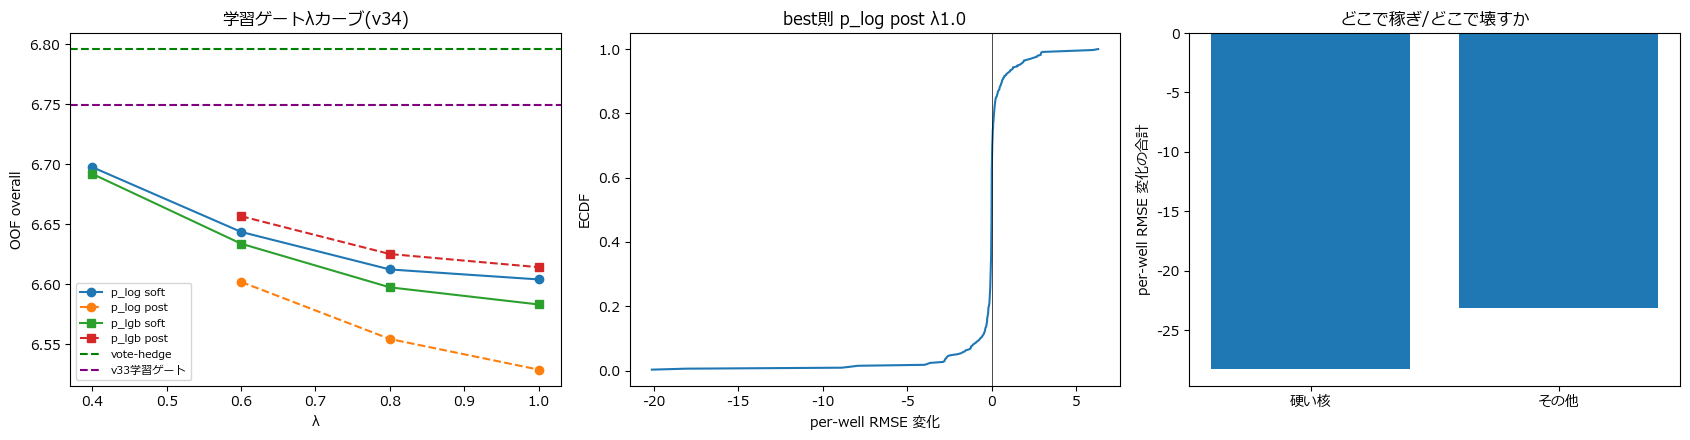

悪化上位(+1.0以上):
  73348914: 11.1 → 17.4
  a4f989c2: 15.1 → 21.1
  7e721392: 5.5 → 9.9
  4c3168cf: 3.3 → 6.3
  52f1e77a: 8.2 → 11.1
  137d1e44: 14.4 → 17.3
  ecdab904: 4.2 → 7.1
  91db7070: 24.7 → 27.4
  ea3a0e38: 4.3 → 7.0
  ee4aecac: 6.0 → 8.5
  89f1085d: 6.9 → 9.2
  fbd68d27: 2.5 → 4.6
  6d590e26: 8.3 → 10.2
  ae0784a8: 1.3 → 3.2
  49dbc14c: 12.2 → 14.0
  d011f41b: 5.3 → 7.1
  fc03f21f: 16.3 → 18.0
  8c167025: 17.2 → 18.7
  6a8fa194: 7.7 → 9.3
  276b012a: 6.2 → 7.5
  653612bc: 15.6 → 16.8
  f16e25e3: 2.3 → 3.5
  84633df4: 8.9 → 10.0
  9283ae69: 7.1 → 8.2
  5305524b: 7.9 → 8.9


In [5]:
# ===== ゲート3: 学習ゲート(GroupKFold OOF) → soft posterior-mean =====
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb

X = np.nan_to_num(TBL[FEATS].to_numpy(dtype=float), nan=-999.0)
yb = TBL["y"].to_numpy(); grp = TBL["well"].to_numpy()
p_lgb = np.zeros(len(TBL)); p_log = np.zeros(len(TBL))
for tr, va in GroupKFold(5).split(X, yb, grp):
    mdl = lgb.LGBMClassifier(n_estimators=250, learning_rate=0.05, num_leaves=7,
                             min_child_samples=25, subsample=0.9, colsample_bytree=0.8,
                             reg_lambda=1.0, verbose=-1)
    mdl.fit(X[tr], yb[tr]); p_lgb[va] = mdl.predict_proba(X[va])[:, 1]
    sc = StandardScaler().fit(X[tr])
    lo = LogisticRegression(C=0.3, max_iter=2000).fit(sc.transform(X[tr]), yb[tr])
    p_log[va] = lo.predict_proba(sc.transform(X[va]))[:, 1]
auc_lgb = roc_auc_score(yb, p_lgb); auc_log = roc_auc_score(yb, p_log)
print(f"OOF AUC: LGBM {auc_lgb:.3f} / Logistic {auc_log:.3f}(v33: 0.768/0.801)")

TBL["p_lgb"], TBL["p_log"] = p_lgb, p_log
def apply_gate(pcol, lam, thr=None, agg="soft"):
    """agg: soft=top1モードに λ·p·c / hard=top1に λ·c / post=全モード確率加重posterior-mean
    (postはユーザー案「1本commitでなくn本を信頼度加重平均」のモード版。stay重み=1−max p)"""
    out = blend.copy()
    for w, sub in TBL.groupby("well"):
        p = sub[pcol].to_numpy(dtype=float); c = sub["c"].to_numpy(dtype=float)
        if agg == "post":
            w_stay = max(0.0, 1.0 - float(p.max()))
            norm = w_stay + float(p.sum())
            if norm <= 1e-9:
                continue
            out[rows_of[w]] += lam * float((p * c).sum()) / norm
        else:
            j = int(np.argmax(p))
            if thr is not None and p[j] < thr:
                continue
            out[rows_of[w]] += lam * (p[j] * c[j] if agg == "soft" else c[j])
    return out

res = []
for name in ["p_log", "p_lgb"]:
    for lam in [0.4, 0.6, 0.8, 1.0]:
        res.append(dict(rule=f"{name} soft λ{lam}", pcol=name, lam=lam, thr=np.nan, agg="soft",
                        overall=rmse(apply_gate(name, lam, None, "soft") - tvt_true)))
    for lam in [0.6, 0.8, 1.0]:
        res.append(dict(rule=f"{name} post λ{lam}", pcol=name, lam=lam, thr=np.nan, agg="post",
                        overall=rmse(apply_gate(name, lam, None, "post") - tvt_true)))
    for thr in [0.4, 0.5, 0.6]:
        res.append(dict(rule=f"{name} hard λ0.4 p>={thr}", pcol=name, lam=0.4, thr=thr, agg="hard",
                        overall=rmse(apply_gate(name, 0.4, thr, "hard") - tvt_true)))
R = pd.DataFrame(res).sort_values("overall")
print(f"基準: blend {base_overall:.4f} / vote-hedge 6.7960 / ★v33学習ゲート 6.7492 / oracle併合 {or_all:.4f}")
print(R[["rule", "overall"]].to_string(index=False))

b = R.iloc[0]
out = apply_gate(b["pcol"], b["lam"], None if not np.isfinite(b["thr"]) else b["thr"], b["agg"])
per_new = {w: rmse((out - tvt_true)[rows_of[w]]) for w in wid}
gated = list(TBL["well"].unique()); dd = {w: per_new[w] - per_base[w] for w in gated}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name, mark in [("p_log", "o"), ("p_lgb", "s")]:
    for agg, ls in [("soft", "-"), ("post", "--")]:
        sub = R[(R["pcol"] == name) & (R["agg"] == agg)].sort_values("lam")
        ax[0].plot(sub["lam"], sub["overall"], mark + ls, label=f"{name} {agg}")
ax[0].axhline(6.7960, c="g", ls="--", label="vote-hedge")
ax[0].axhline(6.7492, c="purple", ls="--", label="v33学習ゲート")
ax[0].set_xlabel("λ"); ax[0].set_ylabel("OOF overall"); ax[0].legend(fontsize=8)
ax[0].set_title("学習ゲートλカーブ(v34)")
v = np.sort(list(dd.values()))
ax[1].plot(v, np.arange(1, len(v) + 1) / len(v)); ax[1].axvline(0, c="k", lw=0.5)
ax[1].set_xlabel("per-well RMSE 変化"); ax[1].set_ylabel("ECDF"); ax[1].set_title(f"best則 {b['rule']}")
ax[2].bar(["硬い核", "その他"], [sum(dd[w] for w in gated if w in HARD),
                                   sum(dd[w] for w in gated if w not in HARD)])
ax[2].set_ylabel("per-well RMSE 変化の合計"); ax[2].set_title("どこで稼ぎ/どこで壊すか")
plt.tight_layout(); plt.show()
print("悪化上位(+1.0以上):")
for w in sorted(gated, key=lambda w: -dd[w]):
    if dd[w] > 1.0:
        print(f"  {w}: {per_base[w]:.1f} → {per_new[w]:.1f}")


In [6]:
# ===== 判定サマリと保存 =====
verdict = dict(
    base_overall=base_overall, free_shift_oracle=fs_overall,
    oracle_ref=or_ref, oracle_seed=or_seed, oracle_all=or_all,
    recovery_ref=rec(or_ref), recovery_seed=rec(or_seed), recovery_all=rec(or_all),
    auc_univariate={k: float(v) for k, v in A.items()},
    auc_oof=dict(lgb=float(auc_lgb), log=float(auc_log)),
    best_rule=str(R.iloc[0]["rule"]), best_overall=float(R.iloc[0]["overall"]),
    ref_v33_gate=6.7492, ref_vote_hedge=6.7960,
    n_split_wells=int(TBL["well"].nunique()), new_cov_wells=len(new_cov))
(ART / "mode_gate_results_v34.json").write_text(json.dumps(verdict, indent=1))
TBL.to_csv(ART / "mode_table_v34.csv", index=False)
print("=" * 70)
print(f"ゲート1(候補拡充): 回収率 {rec(or_ref):.0f}%(平均9本) → {rec(or_all):.0f}%(併合)"
      f" / seed新規カバー {len(new_cov)}井戸")
print(f"ゲート2(新特徴): ext_seed_mass {A.get('ext_seed_mass', float('nan')):.3f}"
      f" / xm_nbr {A.get('xm_nbr', float('nan')):.3f} / xm_self {A.get('xm_self', float('nan')):.3f}"
      f"(v33最良 ext_vote 0.821)")
print(f"ゲート3(学習ゲート): {R.iloc[0]['overall']:.4f} vs v33 6.7492 →"
      f" {'PASS(hedge置換候補を更新)' if R.iloc[0]['overall'] < 6.7492 else 'FAIL(v33版据え置き)'}")
print("保存:", ART / "mode_gate_results_v34.json", "/", ART / "mode_table_v34.csv")


ゲート1(候補拡充): 回収率 25%(平均9本) → 31%(併合) / seed新規カバー 7井戸
ゲート2(新特徴): ext_seed_mass 0.926 / xm_nbr 0.770 / xm_self 0.771(v33最良 ext_vote 0.821)
ゲート3(学習ゲート): 6.5288 vs v33 6.7492 → PASS(hedge置換候補を更新)
保存: C:\Users\kosaka256\Documents\rogii_claude\v34\artifacts_v34\mode_gate_results_v34.json / C:\Users\kosaka256\Documents\rogii_claude\v34\artifacts_v34\mode_table_v34.csv
